## 0: Load the data

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../content_libraries/netflix2022.csv")

df[[
    "imdb_id",
    "title",
    "imdb_score",
    "imdb_votes",
    "imdb_score_2026",
    "imdb_votes_2026"
]].head()

,imdb_id,title,imdb_score,imdb_votes,imdb_score_2026,imdb_votes_2026
0,NaN,Five Came Back: The Reference Films,NaN,NaN,NaN,NaN
1,tt0075314,Taxi Driver,8.2,808582.0,8.2,1044461.0
2,tt0068473,Deliverance,7.7,107673.0,7.6,130378.0
3,tt0071853,Monty Python and the Holy Grail,8.2,534486.0,8.1,608735.0
4,tt0061578,The Dirty Dozen,7.7,72662.0,7.7,84930.0


## 1: Clean the IMDb columns

In [48]:
score_cols = [
    "imdb_score",
    "imdb_score_2026",
]

vote_cols = [
    "imdb_votes",
    "imdb_votes_2026",
]

for col in score_cols + vote_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

comparison = df.dropna(
    subset=[
        "imdb_score",
        "imdb_score_2026",
        "imdb_votes",
        "imdb_votes_2026"
    ]
).copy()

print(f"Original movies/shows: {len(df):,}")
print(f"Movies/shows available for comparison: {len(comparison):,}")

Original movies/shows: 5,850
Movies/shows available for comparison: 5,168


## 3: Calculate the imdb score changes in the 2022 catalog

In [49]:
comparison["score_change"] = (
    comparison["imdb_score_2026"] -
    comparison["imdb_score"]
)
comparison["votes_change"] = (
    comparison["imdb_votes_2026"] -
    comparison["imdb_votes"]
)
comparison["votes_change_pct"] = (
    comparison["votes_change"] /
    comparison["imdb_votes"] * 100
)

In [50]:
summary = pd.DataFrame({
    "Metric": [
        "Average IMDb score",
        "Average IMDb score in 2026",
        "Average score change",
        "Median score change",
        "Average votes",
        "Average votes in 2026",
        "Average vote change",
        "Median vote change",
        "Average vote % change"
    ],
    "Value": [
        comparison["imdb_score"].mean(),
        comparison["imdb_score_2026"].mean(),
        comparison["score_change"].mean(),
        comparison["score_change"].median(),
        comparison["imdb_votes"].mean(),
        comparison["imdb_votes_2026"].mean(),
        comparison["votes_change"].mean(),
        comparison["votes_change"].median(),
        comparison["votes_change_pct"].mean()
    ]
})

summary

,Metric,Value
0,Average IMDb score,6.509694
1,Average IMDb score in 2026,6.519292
2,Average score change,0.009598
3,Median score change,0.000000
4,Average votes,23853.743808
5,Average votes in 2026,31096.420472
6,Average vote change,7242.676664
7,Median vote change,700.500000
8,Average vote % change,1069.033296


## 4: Which movies/shows gained/lost the most IMDb score?

In [51]:
comparison.sort_values(
    "score_change",
    ascending=False
)[[
    "title",
    "imdb_id",
    "imdb_score",
    "imdb_score_2026",
    "score_change"
]].head(20)

,title,imdb_id,imdb_score,imdb_score_2026,score_change
19,Dostana,tt0080653,2.1,6.4,4.3
348,Pocoyo,tt0487849,3.9,7.1,3.2
588,EMI,tt21160742,4.4,7.4,3.0
2838,A House of Blocks,tt7053684,2.3,5.2,2.9
1104,Chhota Bheem Dus pe Dus,tt6417940,5.1,7.3,2.2
1940,The Titan,tt6973848,4.8,6.9,2.1
1629,Love Storm,tt6093070,5.5,7.4,1.9
2821,Learning Songs by Little Baby Bum: Nursery Rhy...,tt11456582,4.2,6.0,1.8
1898,Zoids Wild,tt12317724,6.2,8.0,1.8
4728,How To Build a Sex Room,tt21030224,5.3,7.0,1.7


In [52]:
comparison.sort_values(
    "score_change",
    ascending=True
)[[
    "title",
    "imdb_id",
    "imdb_score",
    "imdb_score_2026",
    "score_change"
]].head(20)

,title,imdb_id,imdb_score,imdb_score_2026,score_change
3132,The Family,tt11056808,6.4,2.0,-4.4
2192,GHOUL,tt5811766,8.0,5.1,-2.9
5365,Taarak Mehta Kka Chhota Chashmah,tt14438518,6.6,3.7,-2.9
1092,Chhota Bheem & Krishna vs Zimbara,tt6417984,9.1,6.4,-2.7
5448,Ridley Jones,tt13351440,4.6,2.0,-2.6
4966,Godse,tt15509164,8.2,5.7,-2.5
2130,Cry Babies Magic Tears,tt11067738,5.2,2.8,-2.4
4355,Omo Ghetto: The Saga,tt14099462,7.5,5.3,-2.2
722,LEGO Friends,tt4049416,7.6,5.4,-2.2
1561,The Governor,tt7128052,7.3,5.3,-2.0


## 5: Which movies/shows gained the most votes

In [53]:
comparison.sort_values(
    "votes_change",
    ascending=False
)[[
    "title",
    "imdb_id",
    "imdb_votes",
    "imdb_votes_2026",
    "votes_change",
    "votes_change_pct"
]].head(20)

,title,imdb_id,imdb_votes,imdb_votes_2026,votes_change,votes_change_pct
216,Breaking Bad,tt0903747,1775990.0,2686770.0,910780.0,5.128295e+01
1123,Stranger Things,tt4574334,1101055.0,1744147.0,643092.0,5.840689e+01
237,Inception,tt1375666,2294231.0,2876462.0,582231.0,2.537805e+01
97,Forrest Gump,tt0109830,2021343.0,2541581.0,520238.0,2.573724e+01
94,Se7en,tt0114369,1606270.0,2065614.0,459344.0,2.859694e+01
651,Django Unchained,tt1853728,1472668.0,1918238.0,445570.0,3.025597e+01
1121,Better Call Saul,tt3032476,438575.0,868896.0,430321.0,9.811800e+01
835,Attack on Titan,tt2560140,325381.0,751464.0,426083.0,1.309489e+02
645,The Dark Knight Rises,tt1345836,1669067.0,2031524.0,362457.0,2.171614e+01
4719,Squid Game,tt10919420,426967.0,779015.0,352048.0,8.245321e+01


## 6: Score distribution

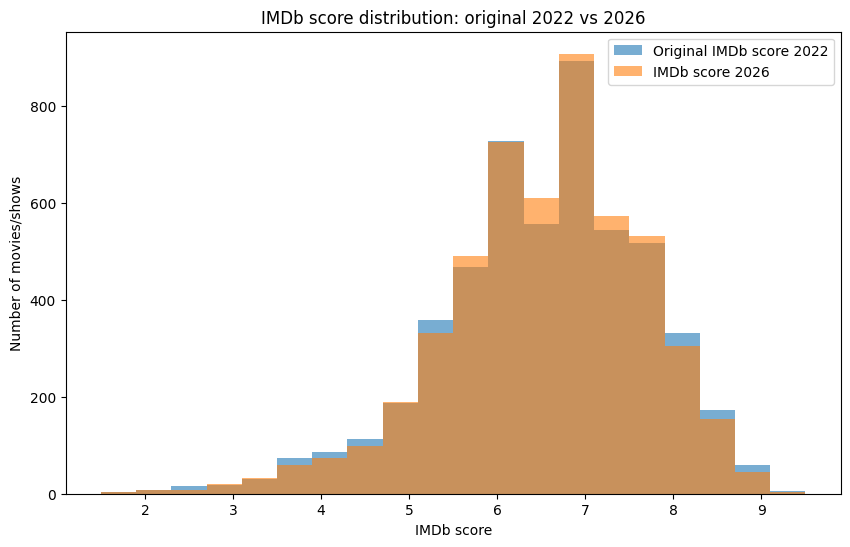

In [54]:
plt.figure(figsize=(10, 6))

plt.hist(
    comparison["imdb_score"],
    bins=20,
    alpha=0.6,
    label="Original IMDb score 2022"
)

plt.hist(
    comparison["imdb_score_2026"],
    bins=20,
    alpha=0.6,
    label="IMDb score 2026"
)

plt.xlabel("IMDb score")
plt.ylabel("Number of movies/shows")
plt.title("IMDb score distribution: original 2022 vs 2026")
plt.legend()
plt.show()

## 7: Score change distribution

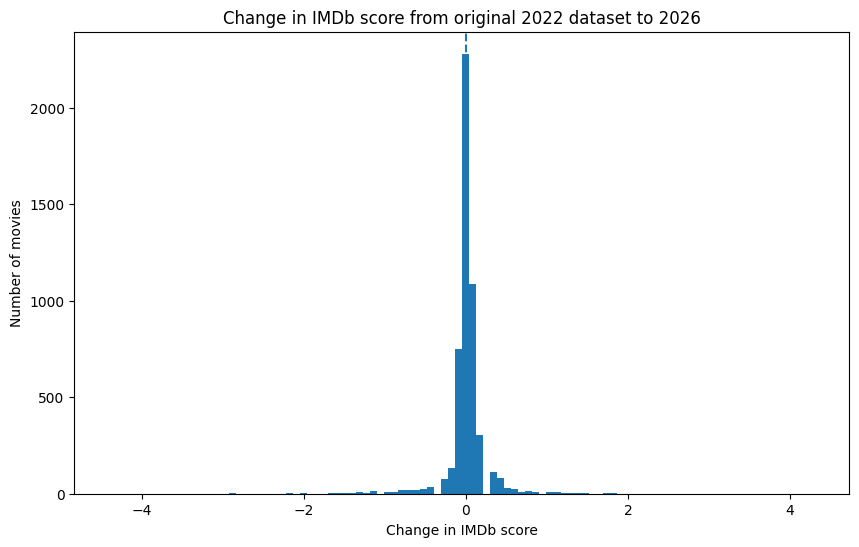

In [55]:
plt.figure(figsize=(10, 6))

plt.hist(
    comparison["score_change"],
    bins=100
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Change in IMDb score")
plt.ylabel("Number of movies")
plt.title("Change in IMDb score from original 2022 dataset to 2026")

plt.show()

## 8: Original 2022 score vs 2026

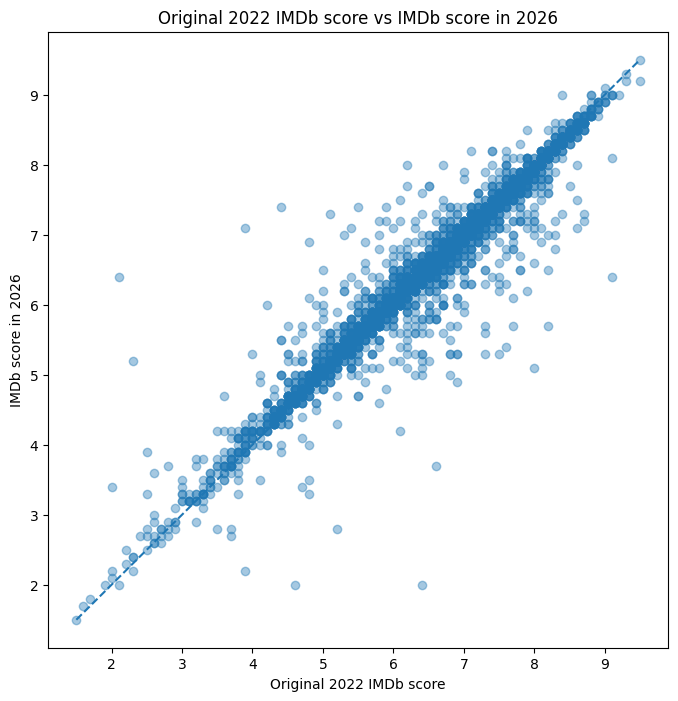

In [56]:
plt.figure(figsize=(8, 8))

plt.scatter(
    comparison["imdb_score"],
    comparison["imdb_score_2026"],
    alpha=0.4
)

plt.xlabel("Original 2022 IMDb score")
plt.ylabel("IMDb score in 2026")
plt.title("Original 2022 IMDb score vs IMDb score in 2026")

# Reference line: no change
min_score = min(
    comparison["imdb_score"].min(),
    comparison["imdb_score_2026"].min()
)

max_score = max(
    comparison["imdb_score"].max(),
    comparison["imdb_score_2026"].max()
)

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.show()

## 9: Correlation between old and new scores

In [61]:
score_correlation = comparison[
    ["imdb_score", "imdb_score_2026"]
].corr().iloc[0, 1]

print(f"Correlation: {score_correlation:.4f}")

vote_correlation = comparison[
    ["imdb_votes", "imdb_votes_2026"]
].corr().iloc[0, 1]

print(f"Vote correlation: {vote_correlation:.4f}")

Correlation: 0.9668
Vote correlation: 0.9918


## 10: How many movies increased/decreased?

In [58]:
score_increased = (comparison["score_change"] > 0).sum()
score_decreased = (comparison["score_change"] < 0).sum()
score_unchanged = (comparison["score_change"] == 0).sum()

print("Score increased:", score_increased)
print("Score decreased:", score_decreased)
print("Score unchanged:", score_unchanged)

total = len(comparison)

print(f"Increased: {score_increased / total * 100:.2f}%")
print(f"Decreased: {score_decreased / total * 100:.2f}%")
print(f"Unchanged: {score_unchanged / total * 100:.2f}%")

Score increased: 1720
Score decreased: 1167
Score unchanged: 2281
Increased: 33.28%
Decreased: 22.58%
Unchanged: 44.14%


## 11: Vote growth

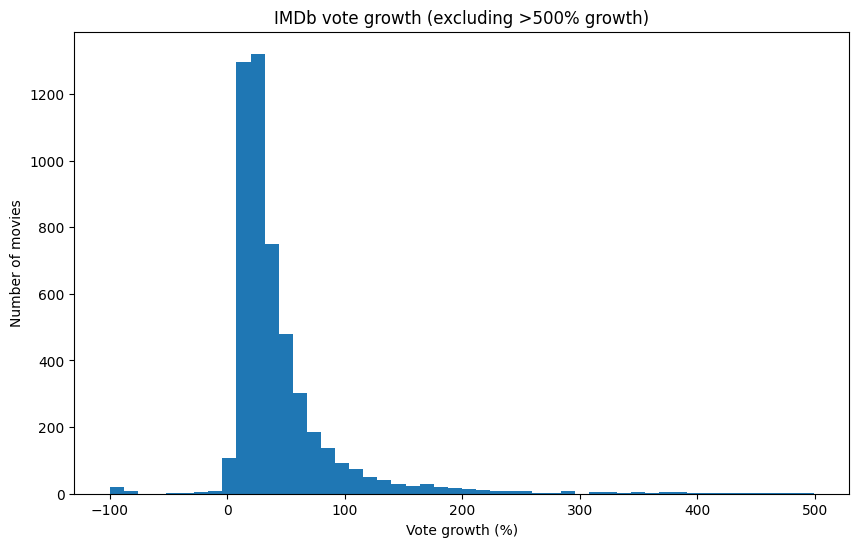

In [59]:
plot_data = comparison[
    comparison["votes_change_pct"] < 500
]

plt.figure(figsize=(10, 6))

plt.hist(
    plot_data["votes_change_pct"],
    bins=50
)

plt.xlabel("Vote growth (%)")
plt.ylabel("Number of movies")
plt.title("IMDb vote growth (excluding >500% growth)")

plt.show()

## 12: Vote growth vs score change

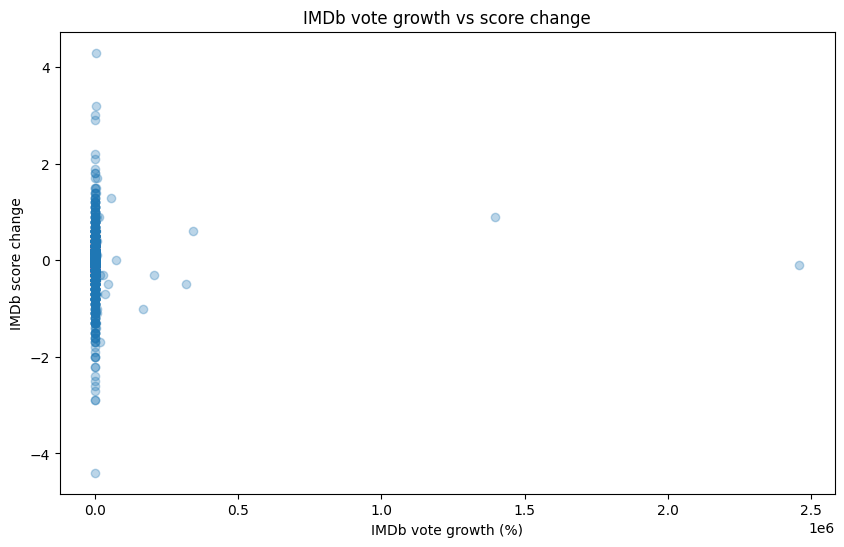

Correlation between vote growth and score change: 0.0128


In [60]:
plt.figure(figsize=(10, 6))

plt.scatter(
    comparison["votes_change_pct"],
    comparison["score_change"],
    alpha=0.3
)

plt.xlabel("IMDb vote growth (%)")
plt.ylabel("IMDb score change")
plt.title("IMDb vote growth vs score change")

plt.show()
correlation = comparison[
    ["votes_change_pct", "score_change"]
].corr().iloc[0, 1]

print(
    f"Correlation between vote growth and score change: "
    f"{correlation:.4f}"
)